In [9]:
options(repr.plot.res = 250, repr.plot.height = 3, repr.plot.width = 5)

In [1]:
library('tidymodels')

gss <- read.csv('https://raw.githubusercontent.com/UNC-BIOS-512/jupyterlite/main/data/gss_subset.csv')

gss |> glimpse()

── Attaching packages ─────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels 1.4.1 ──
✔ broom        1.0.13     ✔ recipes      1.4.0 
✔ dials        1.4.4      ✔ rsample      1.3.2 
✔ dplyr        1.2.1      ✔ tailor       0.1.0 
✔ ggplot2      4.0.3      ✔ tidyr        1.3.2 
✔ infer        1.1.0      ✔ tune         2.1.0 
✔ modeldata    1.6.0      ✔ workflows    1.3.0 
✔ parsnip      1.6.1      ✔ workflowsets 1.1.1 
✔ purrr        1.2.2      ✔ yardstick    1.4.0 
── Conflicts ────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────────── tidymodels_conflicts() ──
✖ tidyr::complete() masks hera::complete()
✖ purrr::discard()  masks scales::discard()
✖ dplyr::filter()   masks stats::filter()
✖ dplyr::lag()      masks stats::lag()
✖ recipes::step()   masks stats::step()
• Learn how to get started at https://www.tidymodels.org/start/


Rows: 75,699
Columns: 8
$ year    <int> 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 1972, 19…
$ id      <int> 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18,…
$ age     <int> 23, 70, 48, 27, 61, 26, 28, 27, 21, 30, 30, 56, 54, 49, 41, 54…
$ educ    <int> 16, 10, 12, 17, 12, 14, 13, 16, 12, 12, 13, 6, 9, 8, 9, 14, 14…
$ sex     <int> 2, 1, 2, 2, 2, 1, 1, 1, 2, 2, 2, 1, 1, 2, 1, 1, 1, 2, 2, 2, 1,…
$ gunlaw  <int> 1, 1, 1, 1, 1, 2, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 1, NA…
$ grass   <int> NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA, NA…
$ realinc <dbl> 18951, 24366, 24366, 30458, 50763, 43994, 37226, 13537, 2707, …


Warning message:
“Removed 7968 rows containing missing values or values outside the scale range (`geom_point()`).”


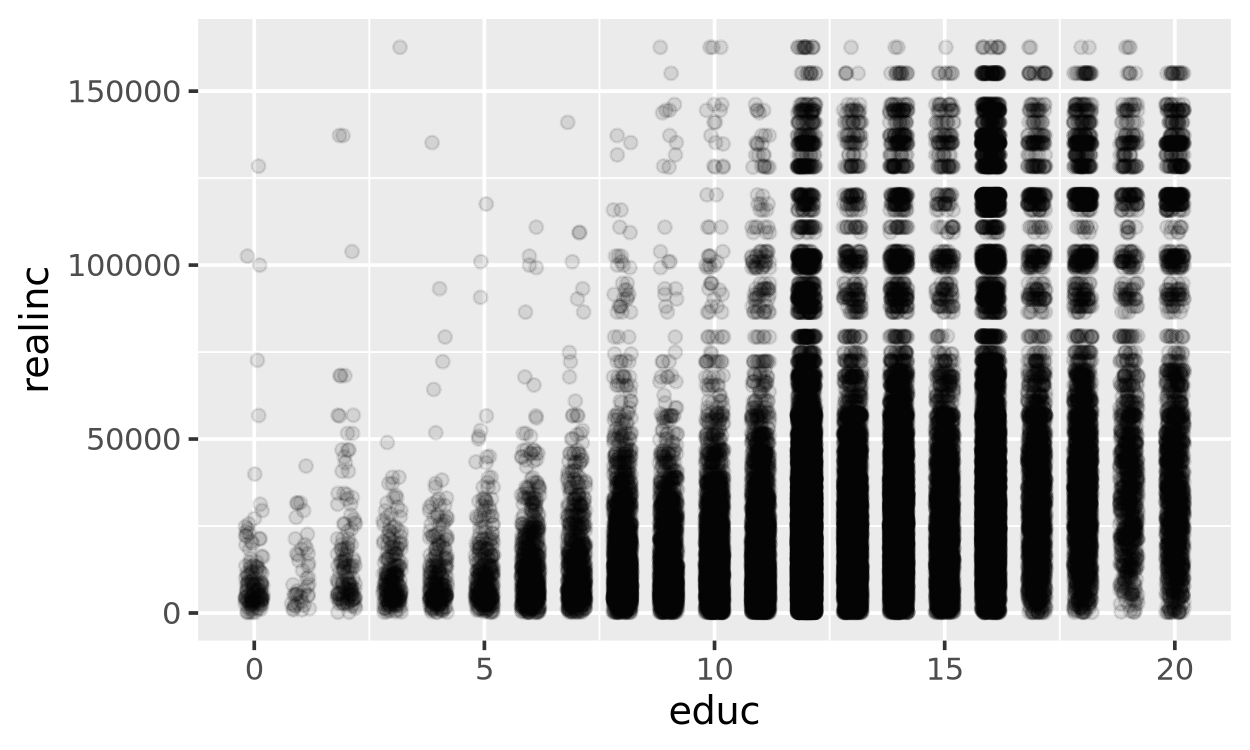

In [12]:
ggplot(gss, aes(x = educ, y = realinc)) +
    geom_point(alpha = 0.1, position = position_jitter(width = 0.2, height = 0))

In [17]:
set.seed(512)

n_combos <- 250

param_grid <- tibble(
  combo     = 1:n_combos,
  intercept = runif(n_combos, 0, 40000),
  slope     = runif(n_combos, -1000, 5000)
)

param_grid |> head()

  combo intercept slope    
1 1     15413.309 1239.2087
2 2      5354.666  169.2174
3 3     18270.370 4682.2865
4 4     37297.365 2279.7293
5 5     25749.956 1865.6305
6 6      7894.540 3629.1521

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


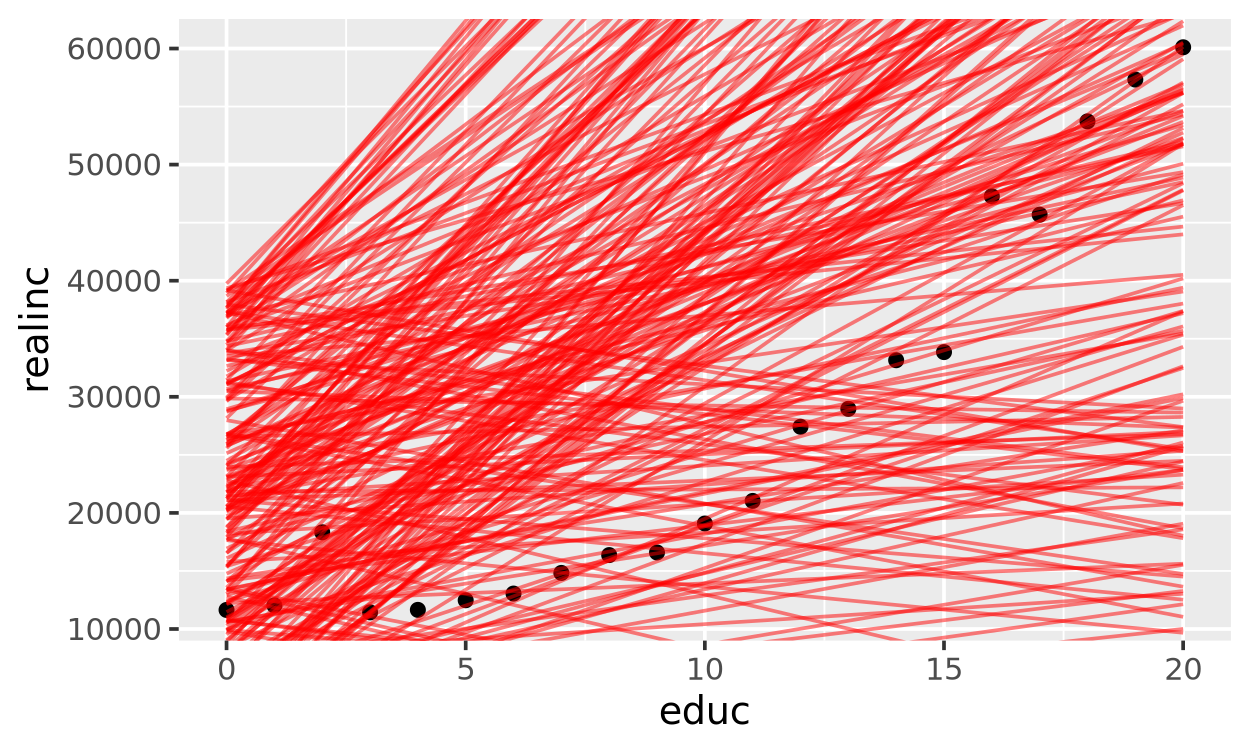

In [19]:
educ_seq <- seq(min(gss$educ, na.rm = TRUE),
                max(gss$educ, na.rm = TRUE),
                length.out = 100)

model_lines <- param_grid |>
  expand_grid(educ = educ_seq) |>
  mutate(realinc = intercept + slope * educ)

educ_means <- gss |>
  group_by(educ) |>
  summarise(realinc = mean(realinc, na.rm = TRUE))

ggplot(educ_means, aes(x = educ, y = realinc)) +
  geom_point() +
  geom_line(data = model_lines, aes(group = combo), colour = "red", alpha = 0.5) +
  coord_cartesian(ylim = range(educ_means$realinc))

Steps for creating a model:

1. pick the model form: a linear model

$$\text{realinc} = \text{intercept} + \text{slope} \cdot \text{educ}$$

2. design a way to evaluate different model parameters
3. optimize out parameter values 

In [20]:
rmse_for_params <- function(intercept, slope, data = gss) {
  pred <- intercept + slope * data$educ
  sqrt(mean((data$realinc - pred)^2, na.rm = TRUE))
}

Warning message:
“Removed 250 rows containing missing values or values outside the scale range (`geom_point()`).”


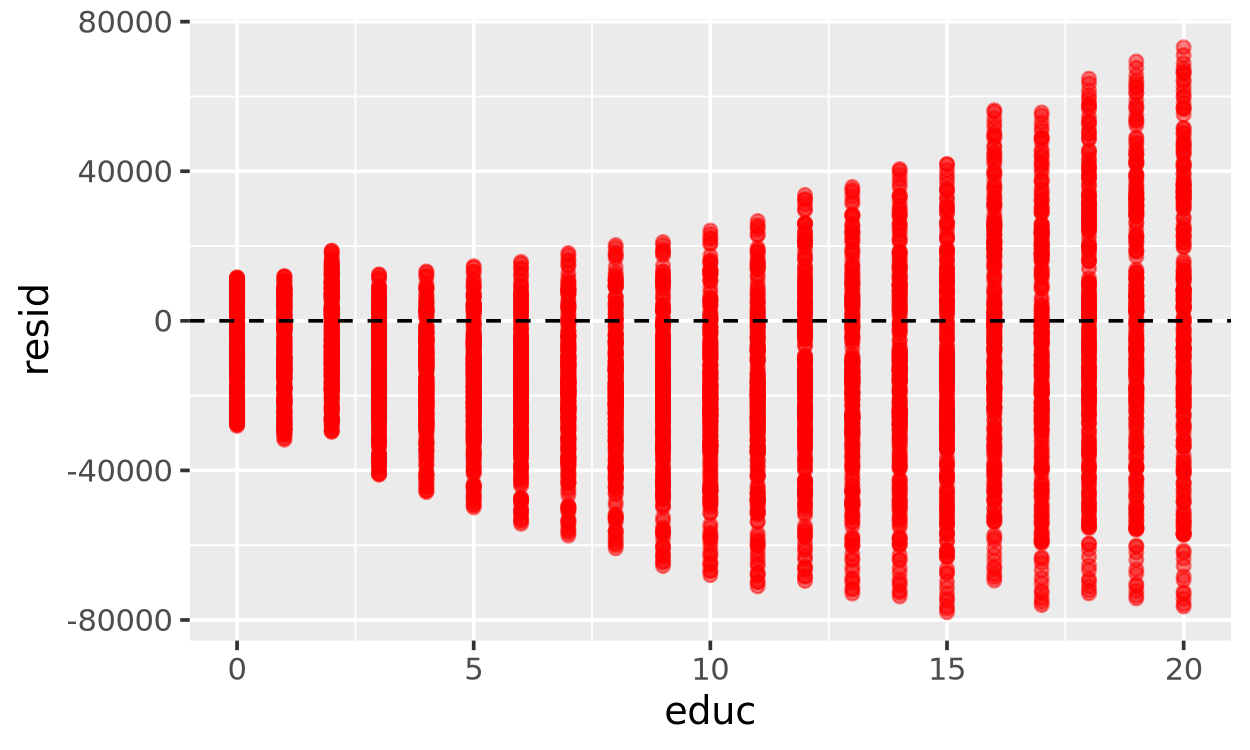

In [27]:
resid_means <- param_grid |>
  expand_grid(educ = educ_means$educ) |>
  left_join(educ_means, by = "educ") |>
  mutate(pred  = intercept + slope * educ,
         resid = realinc - pred)

ggplot(resid_means, aes(x = educ, y = resid, group = combo)) +
  geom_point(colour = "red", alpha = 0.5) +
  geom_hline(yintercept = 0, linetype = "dashed")

In [21]:
param_grid <- param_grid |>
  mutate(rmse = map2_dbl(intercept, slope, rmse_for_params))

param_grid |> head()

  combo intercept slope     rmse    
1 1     15413.309 1239.2087 29258.17
2 2      5354.666  169.2174 39248.09
3 3     18270.370 4682.2865 55223.22
4 4     37297.365 2279.7293 44980.77
5 5     25749.956 1865.6305 33828.44
6 6      7894.540 3629.1521 36509.59

Warning message:
“Removed 1 row containing missing values or values outside the scale range (`geom_point()`).”


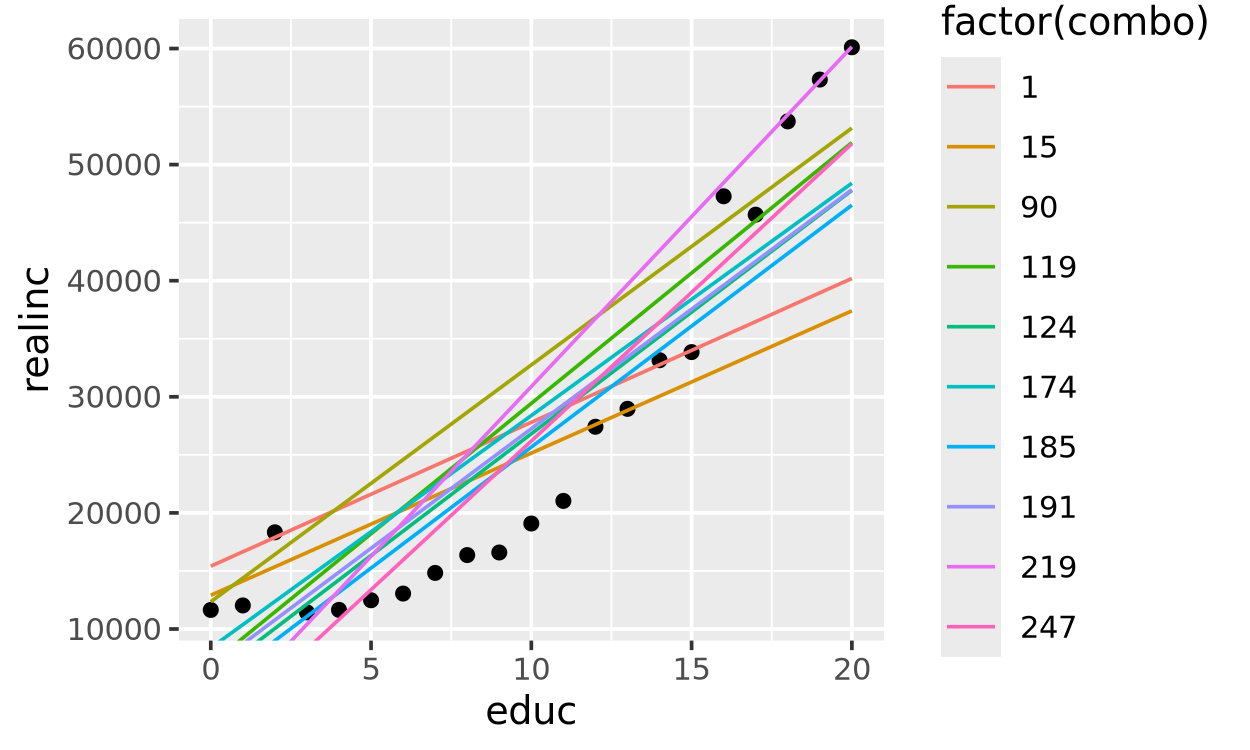

In [31]:
educ_seq <- seq(min(gss$educ, na.rm = TRUE),
                max(gss$educ, na.rm = TRUE),
                length.out = 100)

best_models <- param_grid |>
  slice_min(rmse, n = 10)

model_lines <- best_models |>
  expand_grid(educ = educ_seq) |>
  mutate(realinc = intercept + slope * educ)

educ_means <- gss |>
  group_by(educ) |>
  summarise(realinc = mean(realinc, na.rm = TRUE))

ggplot(educ_means, aes(x = educ, y = realinc)) +
  geom_point() +
  geom_line(data = model_lines, aes(group = combo, colour = factor(combo))) +
  coord_cartesian(ylim = range(educ_means$realinc))